# Project : IRIS (flower) Classification Machine learning model using scikit-Learn

## **Objective**: Build Machine Laerning Model (With maximum accuracy) Classify types of IRIS flower
## **Dataset**:  A well knoown IRIS dataSet from seaborn or skcitlearn library.(Commmonly used to prwactice ML model Developement) 

# Import and setup

In [140]:
!pip install numpy pandas matplotlib seaborn scikit-learn

#EDA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn packages-> 
 # Preprocessing
from sklearn.preprocessing import LabelEncoder ,StandardScaler

 # Model selection
from sklearn.model_selection import train_test_split

 # Model 
from sklearn.linear_model import LogisticRegression

 # Model 
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Warnings
import warnings as w
w.filterwarnings('ignore')

# save model
import pickle


# time stamp
import time as t
print(f"last update:{t.asctime()}")

last update:Sat Oct 24 14:26:46 2026


# Load Dataset

In [141]:
df = sns.load_dataset('iris')
df.head(1)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa


# Exploratory Data Analysis

In [142]:
df.value_counts

<bound method DataFrame.value_counts of      sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]>

In [143]:
df.shape

(150, 5)

In [144]:
df.isnull()

,sepal_length,sepal_width,petal_length,petal_width,species
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [145]:
df.duplicated().sum()

np.int64(1)

In [146]:
df.duplicated().idxmax()

142

In [147]:
df.drop(index = 142 , inplace=True)

In [148]:
df.duplicated().sum()

np.int64(0)

In [149]:
df.duplicated(keep = False).idxmax()

np.int64(0)

In [150]:
df.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

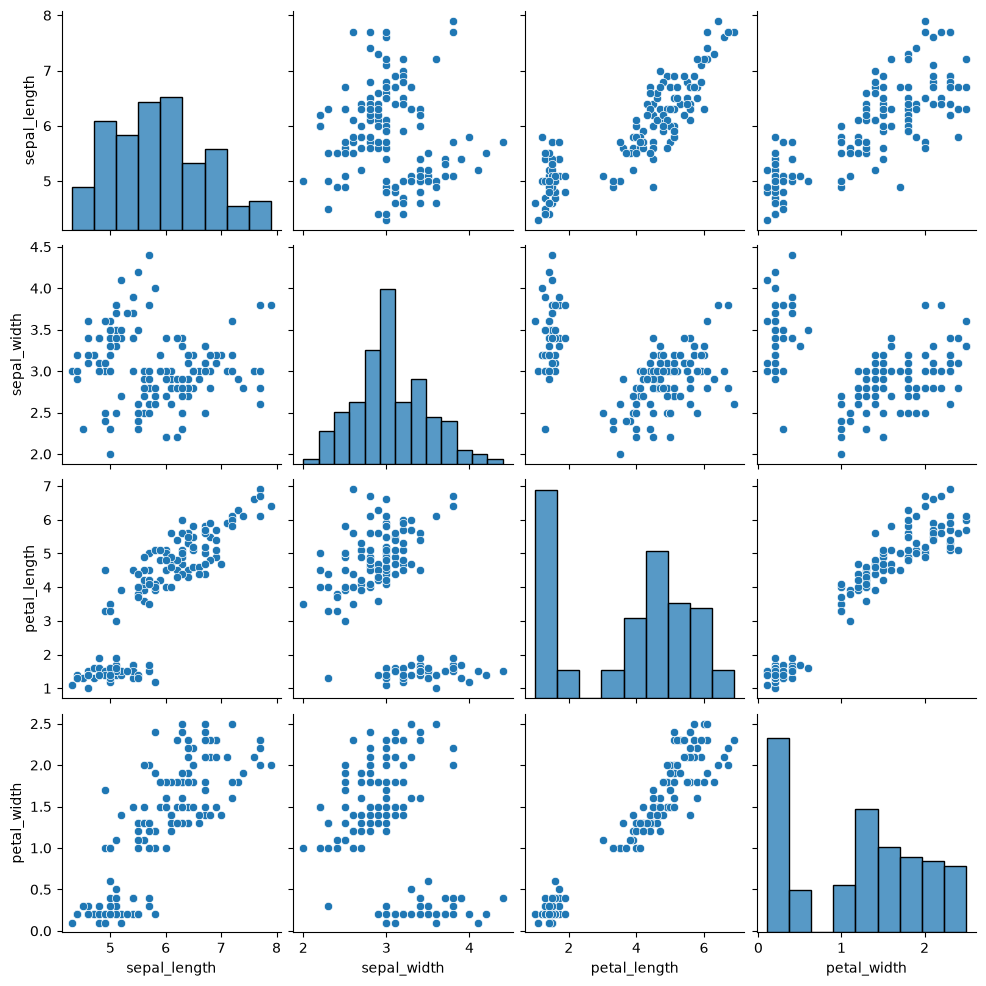

In [151]:
sns.pairplot(df)

In [152]:
df.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


# Preporecessing
## Types:
### Encoding 
1-> lable encoding(more unique) 2-> oneHotencoding(less unique)
### Scalling
1-> lable encoding(more unique) 2-> oneHotencoding(less unique)
### Splitting

### 1. Feature and targets split

In [153]:
X = df.drop('species', axis= 1)
y = df['species']
x.shape, y.shape

((149, 4), (149,))

### 2. Encodeing the target feature

In [154]:
# Encodeing: text ko numaric ma chnage karen gy 
# Encodeing Types: lable Encoding , 

y

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 149, dtype: str

In [155]:
le = LabelEncoder()

y_encoded = le.fit_transform(y)

In [156]:
le.classes_


array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [157]:
y_encoded[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

## 3. Sacling the input Feature 

In [158]:
sc = StandardScaler()

In [159]:
X_scalled = sc.fit_transform(X)

## 4. Train Test Split

In [160]:
X_train, X_test, y_train, y_test = train_test_split(X,y_encoded ,test_size= 0.2)

X_train.shape, X_test.shape,y_train.shape, y_test.shape

((119, 4), (30, 4), (119,), (30,))

## Model Training
### Choose the right model
### 1. Map  2. BroutFouce


### Train: 1. HyperParamTunning ->(gridsearchCV function) -> CrossValidation ->kfold =5


In [161]:
#model object
lr = LogisticRegression()


In [162]:
# train
lr.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [163]:
# Prediction
y_pred = lr.predict(X_test)


In [164]:
y_test[:5], y_pred[:5]

(array([2, 2, 2, 2, 1]), array([2, 2, 2, 2, 1]))

## Model Evaluattion

In [165]:
# accuracy
print(f"Accuaracy score = {accuracy_score(y_test, y_pred)  * 100 : .2f} %")

Accuaracy score =  100.00 %


In [166]:
# Classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



<Axes: >

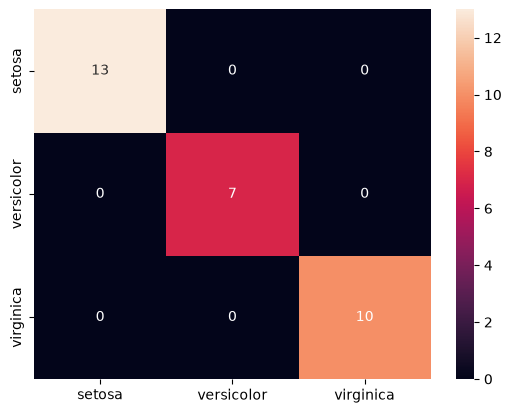

In [167]:
# Confussion Matrix
cm = confusion_matrix(y_test,y_pred)

sns.heatmap(
    cm, xticklabels=le.classes_, yticklabels=le.classes_,annot=True
)

# Save Artifact

In [168]:
artifact = {
    "Model": lr,
    "Scaller": sc,
    "Encoder": le
}

with open('artifact.pkl', 'wb') as f:
    pickle.dump(artifact, f)

# TASK: Shoe Size DataSet



## 1. LOAD DataSet

In [171]:
df = pd.read_csv('shoe_size_dataset.csv')

# 2. Exploratory Data Analysis

In [173]:

df.head(5)

,height_cm,weight_kg,gender,shoe_size_us
0,177.4,96.8,Male,10.0
1,167.7,56.8,Female,6.0
2,156.6,66.4,Female,4.0
3,154.1,78.5,Female,4.0
4,183.3,73.3,Male,9.5


In [174]:
df.tail(5)

,height_cm,weight_kg,gender,shoe_size_us
495,170.3,88.4,Male,9.5
496,158.4,78.4,Female,4.0
497,179.7,73.1,Male,8.5
498,174.9,56.5,Female,6.0
499,166.5,64.7,Female,5.5


In [175]:
df.shape

(500, 4)

In [176]:
df.duplicated().sum()

np.int64(0)

In [177]:
df.dtypes

height_cm       float64
weight_kg       float64
gender              str
shoe_size_us    float64
dtype: object

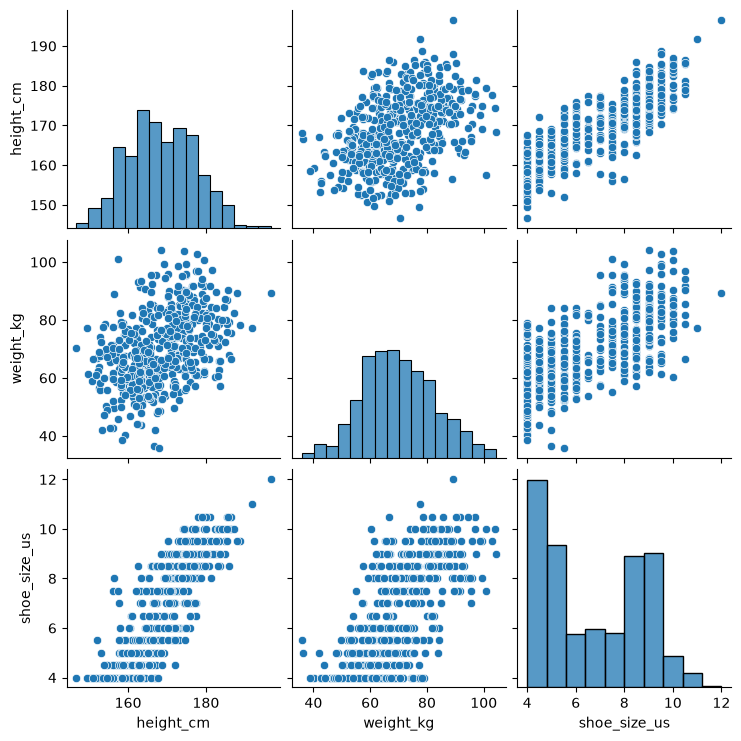

In [178]:
sns.pairplot(df)